<a href="https://colab.research.google.com/github/EthanRod267/AIGuild2026/blob/main/AI_Guild_Auto_Diff_Engines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Building Your Own Auto-Differentiation Engine**

'Ethan Rodriguez'



Let's start with the idea that, through code, we have to calculate the "gradients" or partial derivative for some part of our model with respect to a loss function. How would we approach this? Let's look at different operations and how we could keep count of things manually:

### Addition
$c = a + b$

* **Forward pass**: $c = a + b$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = 1, \quad \frac{\partial c}{\partial b} = 1$$



### Multiplication
$c = a * b$

* **Forward pass**: $c = a * b$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = b, \quad \frac{\partial c}{\partial b} = a$$



### Subtraction
$c = a - b$

* **Forward pass**: $c = a - b$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = 1, \quad \frac{\partial c}{\partial b} = -1$$



### Division
$c = \frac{a}{b}$

* **Forward pass**: $c = a / b$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = \frac{1}{b}, \quad \frac{\partial c}{\partial b} = -\frac{a}{b^2}$$



### Exponent (Base $e$)
$c = e^a$

* **Forward pass**: $c = \exp(a)$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = \exp(a)$$



### Power
$c = a^b$
*(Assuming $a > 0$ for $\ln(a)$ to be well-defined)*

* **Forward pass**: $c = a^b$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = b a^{b-1}, \quad \frac{\partial c}{\partial b} = a^b \ln(a)$$



### Logarithm
$c = \ln(a)$
*(Assuming $a > 0$)*

* **Forward pass**: $c = \ln(a)$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = \frac{1}{a}$$



### Tanh
$c = \tanh(a)$

* **Forward pass**: $c = \tanh(a)$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = 1 - \tanh^2(a)$$



### Sigmoid (Logistic Function)
$c = \sigma(a) = \frac{1}{1 + e^{-a}}$

* **Forward pass**:
$$c = \frac{1}{1 + e^{-a}}$$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = \sigma(a)(1 - \sigma(a)) = c(1 - c)$$



### ReLU (Rectified Linear Unit)
$c = \max(0, a)$

* **Forward pass**:
$$c = \begin{cases} a & \text{if } a > 0 \\ 0 & \text{otherwise} \end{cases}$$
* **Partial derivatives**:
$$\frac{\partial c}{\partial a} = \begin{cases} 1 & \text{if } a > 0 \\ 0 & \text{if } a \le 0 \end{cases}$$

## Let's Create Our Version of Torch Tensor

### Using `__dunder__` methods
We're going to do a version of each/most of these functions, in such a way that we don't need to specify the gradient calculation when we multiply them together.

Python has a very strategic and intuitive way of doing so- we call them dunder methods. They are reserved methods just like the `__init__` method.

### Defining our class

The basic class will follow this structure: a value, and a gradient. This is really similar to how PyTorch does it.

In [1]:
class Tensor_1:
    def __init__(self, data, _op='', label=''):
      self.data = data
      self.grad = 0.0

We'll also add a set of helper parameters for our computation

In [2]:
class Tensor_2:
    def __init__(self, data):
        self.data = data
        self.grad = 0.0

        # This is for printing purposes
        self._op = ''
        self.label = ''


    def __repr__(self):
      return f"Tensor(data={self.data})"

In [3]:
#TODO
print(Tensor_2(2))

Tensor(data=2)


### Creating initial operations w.r.t. our Tensor: Add, Mul, and Sub

In [4]:
class Tensor_3:
    def __init__(self, data, _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Tensor(data={self.data})"

    def __add__(self, other):
        # Tensor(4) + 5 = Tensor(9)
        other = other if isinstance(other, Tensor_3) else Tensor_3(other)
        out = Tensor_3(self.data + other.data, _op='+')
        return out

    def __mul__(self, other):
        # Left multiplication
        other = other if isinstance(other, Tensor_3) else Tensor_3(other)
        out = Tensor_3(self.data * other.data, _op='*')
        return out

    def __neg__(self):
        return self * -1

    # NOTE: this method is the same as calling addition on the negation
    def __sub__(self, other):
        return self + (-other)

In [5]:
first, second = 6,7
result = first + second
print(result)

13


In [6]:
a = Tensor_3(2.0, label='a')
b = Tensor_3(3.0, label='b')
c = Tensor_3(4.0, label='c')


d = a + b
e = b - c
y = d * e

print(c)
print(y)
print(b)

Tensor(data=4.0)
Tensor(data=-5.0)
Tensor(data=3.0)


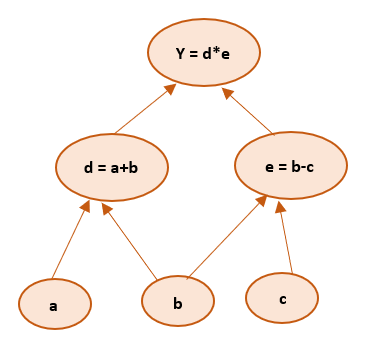

In [8]:
a = Tensor_3(2.0, label='a')
b = Tensor_3(3.0, label='b')
c = Tensor_3(4.0, label='c')

d = a + b
e = b - c
y = d * e

print(d)
print(e)
print(y)

Tensor(data=5.0)
Tensor(data=-1.0)
Tensor(data=-5.0)


### Finishing with all operations

In [9]:
import math # s*** got serious

In [10]:
class Tensor_4:
    def __init__(self, data, _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Tensor(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Tensor_4) else Tensor_4(other)
        out = Tensor_4(self.data + other.data, '+')

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Tensor_4) else Tensor_4(other)
        out = Tensor_4(self.data * other.data, '*')

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Tensor_4(self.data**other, f'**{other}')

        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __radd__(self, other): # other + self
        return other + self

    def __rmul__(self, other): # other * self
        return other * self

    def __truediv__(self, other): # self / other
        return self * other **-1

    # These don't have dunder methods!
    def tanh(self):
      x = self.data
      t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
      out = Tensor_4(t, 'tanh')

      return out

    def exp(self):  # e^x
      x = self.data
      out = Tensor_4(math.exp(x), 'exp')

      return out

    def sine(self):
      x = self.data
      out = Tensor_4(math.sin(x), 'sin')

      return out

    def cosine(self):
      x = self.data
      out = Tensor_4(math.cos(x), 'cos')

      return out

    def sigmoid(self):
      x = self.data
      out = Tensor_4(1 / (1 + math.exp(-x)), 'sigmoid')

      return out


In [11]:
a = Tensor_4(2.0, label='a')
b = Tensor_4(3.0, label='b')
c = Tensor_4(4.0, label='c')

d = (a + b) * c
e = d.exp()
f = d.sigmoid()
g = (a - b).tanh()
h = (c / a).sine()

print("d =", d)
print("e =", e)
print("f =", f)
print("g =", g)
print("h =", h)


d = Tensor(data=20.0)
e = Tensor(data=485165195.4097903)
f = Tensor(data=0.9999999979388463)
g = Tensor(data=-0.7615941559557649)
h = Tensor(data=0.9092974268256817)


# Backpropagation: Using our derivatives!

So far we've established ways to perform basic operations between our tensors. But we haven't defined a way to actually perform the gradients with respect to our operations. To do this, we have to treat these tensors as actual nodes in a graph.

We'll add in these helper parameters:
- `_children`: it represents the nodes that contributed to the current value during creation.
and these fields
- `_backward` : Defining the backward pass function. We'll override it in every primitive method
- `_prev`: Stores a set of nodes (i.e., other Tensor instances) that were used to create the current node. These are the immediate ancestors in the computational graph.

### Here's the idea:
We're defining `_backward` for every operation that will be performed in these tensors. But, we'll need to override them internally when the operations are called. We'll see that the intuition is that we need to compute our gradients topologically. Since the current computation depends on the computations that led to it.


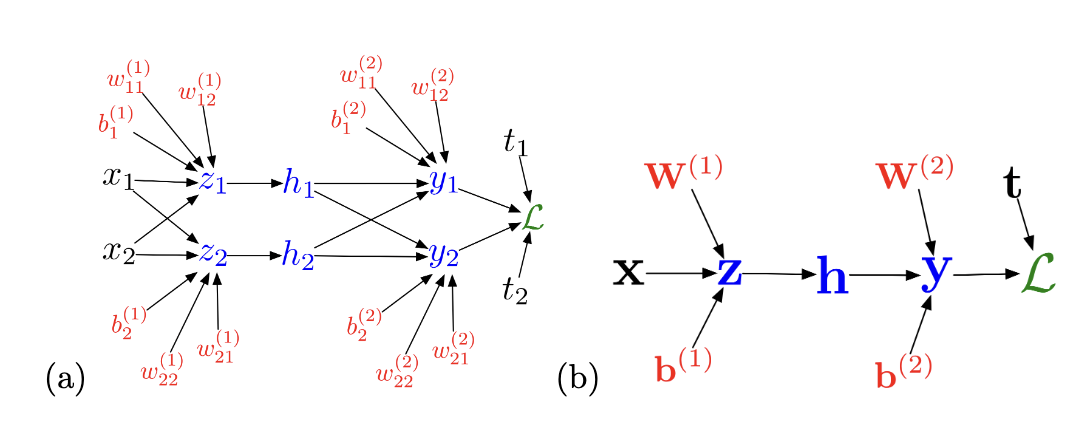


For that reason, we need to define a topological sorting algorithm when we call `.backward()`!

In [32]:
class Tensor:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._op = _op
        self._backward = lambda: None # we'll override this
        self._prev = set(_children)
        self.label = label

    def __repr__(self):
        return f"Tensor(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Tensor) else Tensor(other)
        out = Tensor(self.data + other.data, (self, other), '+')

        def _backward():
          # dy/dx = 1, we multiply by out.grad
          self.grad += 1 * out.grad
          other.grad += 1 * out.grad

        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Tensor) else Tensor(other)
        out = Tensor(self.data * other.data, (self, other), '*')

        def _backward():
          # dy/dx = x
          self.grad += other.data * out.grad
          other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Tensor(self.data**other, (self,), f'**{other}')

        def _backward():
          # dy/dx = n*x^(n-1)
          self.grad += (other * self.data**(other-1)) * out.grad

        out._backward = _backward

        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __radd__(self, other): # other + self
        return self + other

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    # These don't have dunder methods!
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Tensor(t, (self, ), 'tanh')

        def _backward():
          self.grad += (1 - t**2) * out.grad

        return out

    def exp(self): # e^x
        x = self.data
        out = Tensor(math.exp(x), (self, ), 'exp')

        def _backward():
          self.grad += out.data * out.grad

        return out

    def sine(self):
        x = self.data
        out = Tensor(math.sin(x), (self, ), 'sin')

        def _backward():
          self.grad = math.cos(x) * out.grad

        return out

    def cosine(self):
        x = self.data
        out = Tensor(math.cos(x), (self, ), 'cos')

        def _backward():
          self.grad = -math.sin(x) * out.grad

        return out

    def sigmoid(self):
        out = (-(self)).exp()
        out = Tensor(1 / (1 + out.data), (self,), 'sigmoid')

        def _backward():
          self.grad += (out.data * (1 - out.data)) * out.grad
        return out

    def relu(self):
        out = Tensor(0 if self.data < 0 else self.data, (self, ), 'ReLU')

        def _backward():
          self.grad += (out.data > 0) * out.grad

        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
          if v not in visited:
            visited.add(v)
            for child in v._prev:
              build_topo(child)
            topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
          node._backward()

![image](https://miro.medium.com/v2/resize:fit:1400/1*uMg_ojFXts2WZSjcZe4oRQ.png)

# Graphing a Computation Graph a.k.a. "Neural Network"

### Helper function

In [33]:
from graphviz import Digraph

def trace(root):
    nodes ,edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
              edges.add((child, v))
              build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape="record")
        if n._op:
          dot.node(name = uid + n._op, label = n._op)
          dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot. edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

## Backpropagation Example

In [34]:
import random

In [35]:
# Define Tensors
w = Tensor(random.uniform(-1,1), label = 'w')
b = Tensor(random.uniform(-1,1), label = 'b')

In [36]:
def get_batch():
    xs = [random.uniform(-5,5) for _ in range(20)]

    ys = [3.0 * x - 4.0 + random.gauss(0, 0.01) for x in xs]

    return [xs], [ys]

In [37]:
def parameters():
    return [w, b]

In [38]:
for epoch in range(500):
    # Get a batch of data
    x_batch, y_batch = get_batch()
    xs, ys = x_batch[0], y_batch[0]

    # model(x)
    y_pred = [w * xi + b for xi in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, y_pred)])  # MSE loss

    # optimizer.zero_grad()
    for p in parameters():
        p.grad = 0.0
    loss.backward()

    # optimizer.step()
    for p in parameters():
        p.data += -0.001 * p.grad

    if epoch % 50 == 0:
        print(f"Epoch {epoch}: Loss = {loss.data:.4f}, w = {w.data:.4f}, b = {b.data:.4f}")

print(f"\nFinal model: y = {w.data:.4f} * x + {b.data:.4f}")

Epoch 0: Loss = 1649.4281, w = 1.0068, b = -0.3695
Epoch 50: Loss = 5.1922, w = 2.9835, b = -3.5057
Epoch 100: Loss = 0.0944, w = 2.9990, b = -3.9367
Epoch 150: Loss = 0.0022, w = 3.0000, b = -3.9915
Epoch 200: Loss = 0.0022, w = 3.0002, b = -3.9990
Epoch 250: Loss = 0.0017, w = 3.0001, b = -3.9999
Epoch 300: Loss = 0.0012, w = 3.0006, b = -3.9998
Epoch 350: Loss = 0.0035, w = 3.0005, b = -3.9999
Epoch 400: Loss = 0.0024, w = 2.9998, b = -4.0003
Epoch 450: Loss = 0.0011, w = 3.0000, b = -3.9999

Final model: y = 3.0001 * x + -3.9996


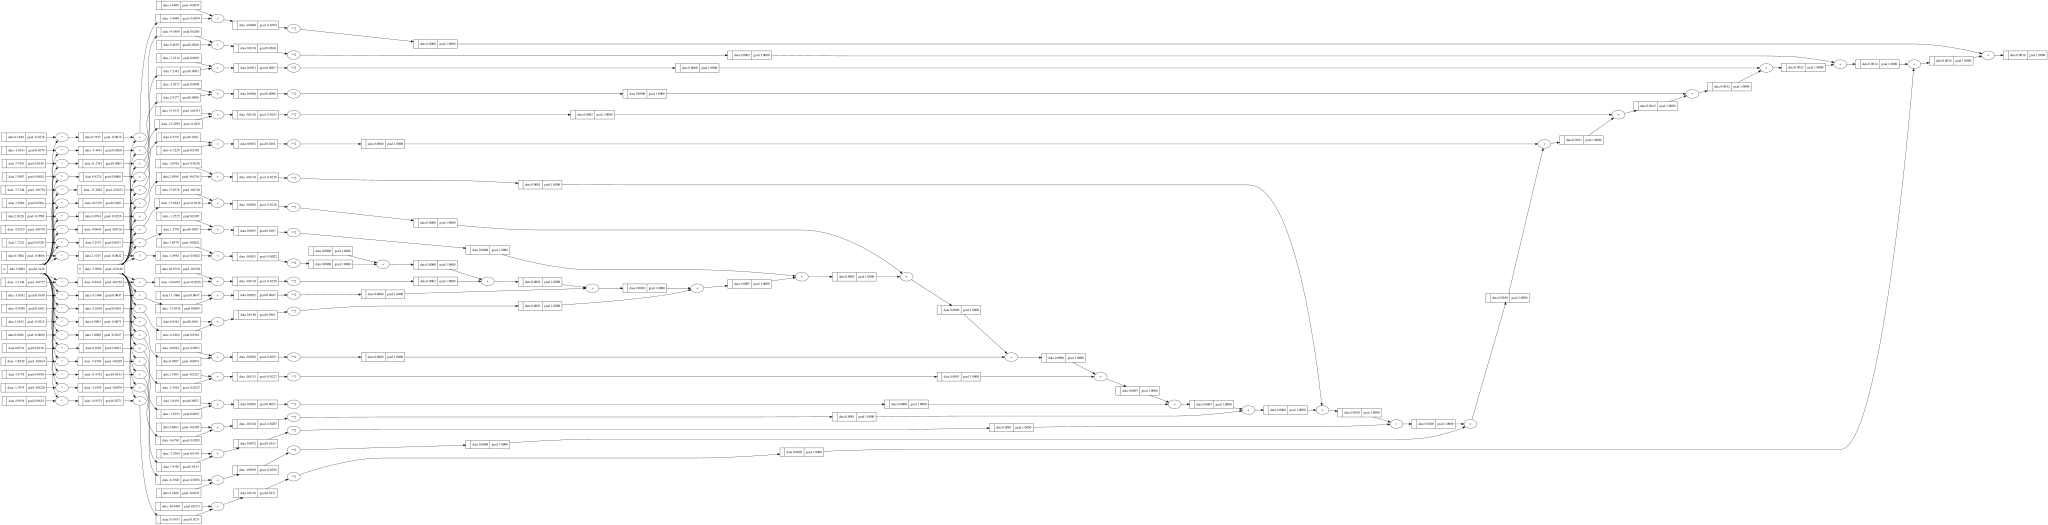

In [39]:
draw_dot(loss)

## Creating a Neural Network with our Tensors

In [40]:
import random

In [41]:
class Module:
    def zero_grad(self):

        for p in self.parameters():
            p.grad = 0.0

        def parameters(self):
            return []

In [55]:
class Neuron(Module):
    def __init__(self, nin, nonlin=True):
        self.w = [Tensor(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Tensor(0)
        self.nonlin = nonlin

    def __call__(self, x):
        activation = sum((wi*xi for wi,xi in zip(self.w, x)), self.b)
        return activation.relu() if self.nonlin else activation

    def parameters(self):
        return self.w + [self.b]

    def __repr__(self):
        return f"{'ReLU' if self.nonlin else 'Linear'}Neuron({len(self.w)})"

In [43]:
class Layer(Module):
    def __init__(self , nin , nout , **kwargs):
        self.neurons = [Neuron(nin , **kwargs) for _ in range(nout)]

    def __call__(self , x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

    def __repr__(self):
        return f"Layer of [{', '.join(str(n) for n in self.neurons)}]"

In [44]:
class MLP(Module):
    def __init__(self , nin , nouts):
        size = [nin] + nouts
        self.layers = [Layer(size[i] , size[i+1] , nonlin=i!=len(nouts)-1) for i in range(len(nouts))]

    def __call__(self , x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def __repr__(self):
        return f"MLP of [{', '.join(str(layer) for layer in self.layers)}]"

### Training Loop using our Custom Functions

In [45]:
# Defining a tiny dataset
# 4 inputs, 3 features each
xs = [
  [2.0 , 3.0 , -1.0],
  [3.0 , -1.0 , 0.5],
  [0.5 , 1.0 , 1.0],
  [1.0 , 1.0 , -1.0]
]

# The target outputs (one per input)
ys = [1.0 , -1.0 , -1.0 , 1.0]

In [56]:
# Initializing the MLP model
# nin = 3 (matches our 3 features per input)
# nouts = [4, 4, 1] -> Two hidden layers with 4 neurons each, and 1 output neuron
model = MLP(3 , [4, 4, 1])

learning_rate = 0.1

In [57]:
for epoch in range(200):
  # Forward pass
  y_pred = [model(x) for x in xs]

  # Loss (MSE)
  loss = sum((yout - ygt)**2 for ygt , yout in zip(ys , y_pred)) * (1.0 / len(xs))

  # Backward pass
  for p in model.parameters():
    p.grad = 0.0  # Zero-ing grads

  loss.backward()

  # Gradient Descent step
  for p in model.parameters():
    p.data -= learning_rate * p.grad

  if epoch % 20 == 0:
    print(f"Epoch {epoch:3d} | Loss: {loss.data:.4f}")

Epoch   0 | Loss: 1.7538
Epoch  20 | Loss: 0.3548
Epoch  40 | Loss: 0.2653
Epoch  60 | Loss: 0.2196
Epoch  80 | Loss: 0.1946
Epoch 100 | Loss: 0.1807
Epoch 120 | Loss: 0.1731
Epoch 140 | Loss: 0.1688
Epoch 160 | Loss: 0.1664
Epoch 180 | Loss: 0.1651


In [58]:
print("Final Predictions:")
for x, y_tgt in zip(xs, ys):
  y_out = model(x)
  print(f"Input: {x} | Target: {y_tgt:4.1f} | Prediction: {y_out.data:.4f}")

Final Predictions:
Input: [2.0, 3.0, -1.0] | Target:  1.0 | Prediction: 0.4993
Input: [3.0, -1.0, 0.5] | Target: -1.0 | Prediction: -0.4221
Input: [0.5, 1.0, 1.0] | Target: -1.0 | Prediction: -1.2344
Input: [1.0, 1.0, -1.0] | Target:  1.0 | Prediction: 1.1324
